In [1]:
import pandas as pd
import re
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
from collections import defaultdict
import numpy as np
import pytz
import re

In [2]:

# Read the list of filenames from the configuration file
with open('file_list.txt', 'r', encoding='utf-8') as config_file:
    file_names = config_file.read().splitlines()

# Regex pattern to match the data format
pattern = r'\[(.*?)\] (.*?): (.*)'

# Initialize an empty list to store parsed data
datalist = []
stream_count = 0
# Iterate over each specified file
for file in file_names:
    full_path = "data\\"+file
    with open(full_path, 'r', encoding='utf-8') as f:
        lines = f.readlines()
        for line in lines:
            match = re.match(pattern, line)
            if match:
                date, user, message = match.groups()
                datalist.append([date, user, message,stream_count])
    stream_count = stream_count + 1

# Create a DataFrame from the parsed data
data = pd.DataFrame(datalist, columns=["date", "user", "message","stream"])

In [3]:
data['date'] = pd.to_datetime(data['date'])

In [4]:
def convert_utc_to_cet(df, date_column='date'):
    """
    Convert UTC timestamps to Central European Time (CET/CEST) with proper DST handling
    
    Parameters:
    df (pd.DataFrame): DataFrame containing the date column
    date_column (str): Name of the column containing UTC timestamps
    
    Returns:
    pd.DataFrame: DataFrame with converted timestamps
    """
    # Make a copy to avoid modifying the original
    df = df.copy()
    
    # Ensure timestamps are UTC aware
    if df[date_column].dt.tz is None:
        df[date_column] = df[date_column].dt.tz_localize('UTC')
    elif df[date_column].dt.tz != pytz.UTC:
        df[date_column] = df[date_column].dt.tz_convert('UTC')
    
    # Convert to CET/CEST (Europe/Berlin includes proper DST handling)
    df[date_column] = df[date_column].dt.tz_convert('Europe/Berlin')
    
    return df


In [5]:
data = convert_utc_to_cet(data)

In [6]:
data["user"] = data["user"].str.lower()

In [7]:
data['user'] = data['user'].replace({
    '5hreyansh1': 'shreyansh_15_',
    '88krille': 'phrank007',
    'abjectuz': 'albazoarr',
    'aboodorten': 'abood_orton',
    'adevogado0_0': 'adevogado__33',
    'akahoroshi': 'damm1jp',
    'banties1g': 'banties_x',
    'beratnazmm': 'beratnzm0',
    'bickcog158': 'oliver_158',
    'boyy966': 'boy_kaa_',
    'cactiesrn': 'staniv4_',
    'cengizkorkmaz00': 'say_i_love_u_',
    'chabibzzo': 'chabbzz4u',
    'chili_conbacon': 'chili_con_bacon',
    'chili_poe': 'chili_con_bacon',
    'cukululu41': 'aransamus64',
    'drizzienm': 'drizzie3s',
    'elecetric1': 'mediterrn1',
    'emin_ko': 'pepegakun',
    'eminkoo': 'pepegakun',
    'emlnko': 'pepegakun',
    'flexus1771_': 'flexus17_',
    'fr__00': 'firas__00',
    'fyyzckrl': 'n1trx_63',
    'happymetalist': 'kindheadbanger',
    'hella__yeahh': 'hella_yeahh',
    'hellrazor_0': 'hellrazor_1',
    'honey2024': 'honneeeeyyy',
    'internetuser3708776': 'notdylll',
    'io69oi': 'dterreneitorb',
    'iomwmoi': 'dterreneitorb',
    'jbinsamboosa': 'jbin2036',
    'jermsywermsy': 'chromejeromee',
    'journee_': 'journee',
    'justlogannnnn': 'loganxdr',
    'karasusora7': '777ultima777',
    'kecso1g': 'kkecso',
    'lajosbarnabas': 'lajoss__',
    'lighttx_': 'lightfx_',
    'luke_nukem118': 'duke_lukem5',
    'lytis_': 'lightfx_',
    'm7mdess': 'kasida_ink',
    'make_matovic_greatagain': 'freemaaan_',
    'mamangracing13': 'iamsatire_',
    'marcusbarcus1': 'marcus_15s',
    'methmethician': 'permission_cheese',
    'muffineater27': 'sillylittlemuffinn',
    'muffinmmn': 'sillylittlemuffinn',
    'n0rth0m': 's4sk__',
    'nat_l0ve': 'scentless_',
    'necrolutz': 'xvette06',
    'nishad_more1311': 'nishad13',
    'nobodysbv': 'fein_bv',
    'nojokeee1': 'magor_35',
    'nuffsaid_17': 'aransamus64',
    'opalshbab7': 'opalmyzeis',
    'orez_prajit': 'luchian03',
    'paulpige0n': 'pige0n98',
    'pepega_kun': 'pepegakun',
    'rizz_lord_69': 'pepegakun',
    'rodrigo_200771': 'rodrigo_20771',
    's4sk____': 's4sk__',
    'sahilsd97': 'unemployedking69',
    'schiken44': 'aransamus64',
    'sheerchild': 'veryloyalgamingfrog',
    'softarballt123': 'softarr',
    'softarballtt': 'softarr',
    'spectraleidolon': 'veryloyalgamingfrog',
    'sproink__': 'sproinkedd',
    'stan_iv4': 'staniv4_',
    'stayoutlive': 'filipstayout',
    'stork9231': 'eyes923',
    'tiberiu0s': 'tiberoo',
    'toni_0000000': 'eyes923',
    'totalbiscuit69': 'portishead___',
    'touchscreen_toaster': 'permission_cheese',
    'trek44_': 'trek_x',
    'treklul': 'trek_x',
    'ttrek_': 'trek_x',
    'tyler1_cant_play_variety': 'e1shayeb',
    'uuccugr': 'turklander__',
    'uuccugr_': 'turklander__',
    'uwu_cougar': 'turklander__',
    'vascao_85': 'v_warr10r',
    'w1r3lesss': 'wirelesss_',
    'wertfhuykjkl': 'skibidiparkurkiller1',
    'winterwolf_audrey1234': 'audrey_w_wolf1150',
    'xniraki': 'xpikarin',
    'xx_atopic_eczema_xx': 'atop1c',
    'yaonbuci': 'allxdx',
    'ylb_cat_soul22': '4ylb_cat_soul22_1',
})

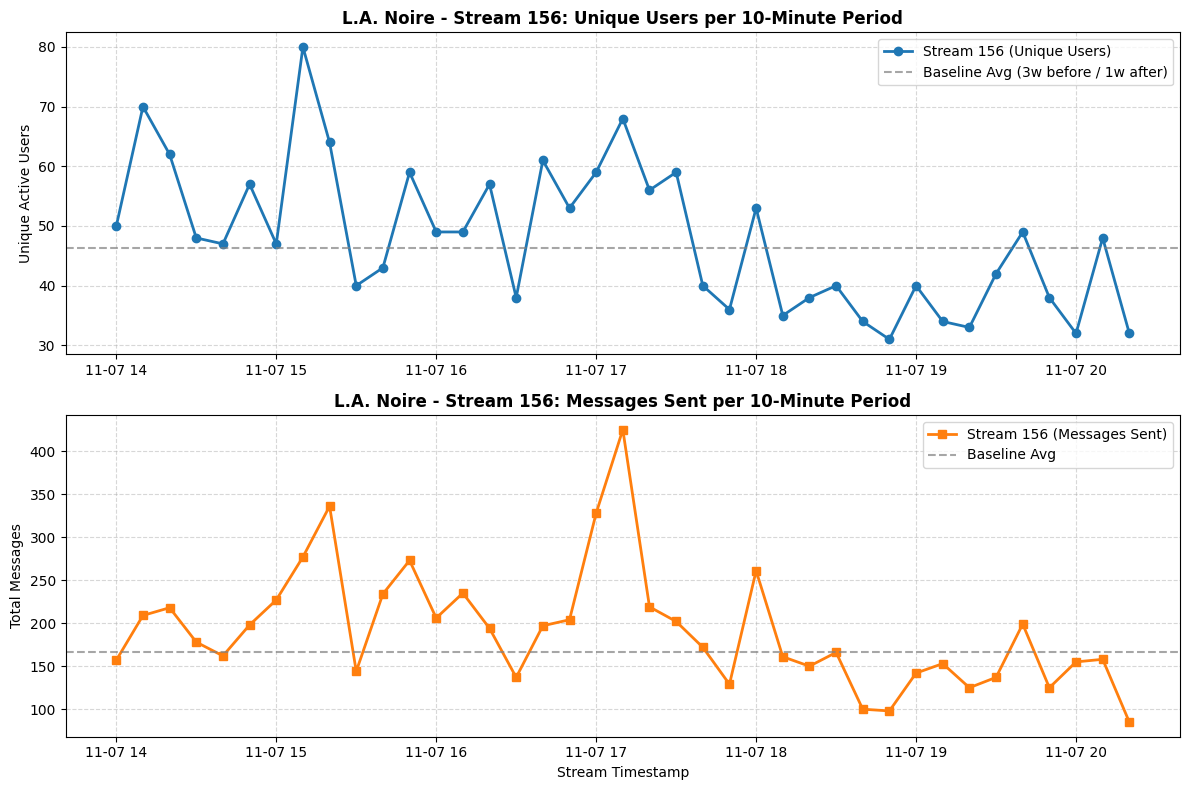

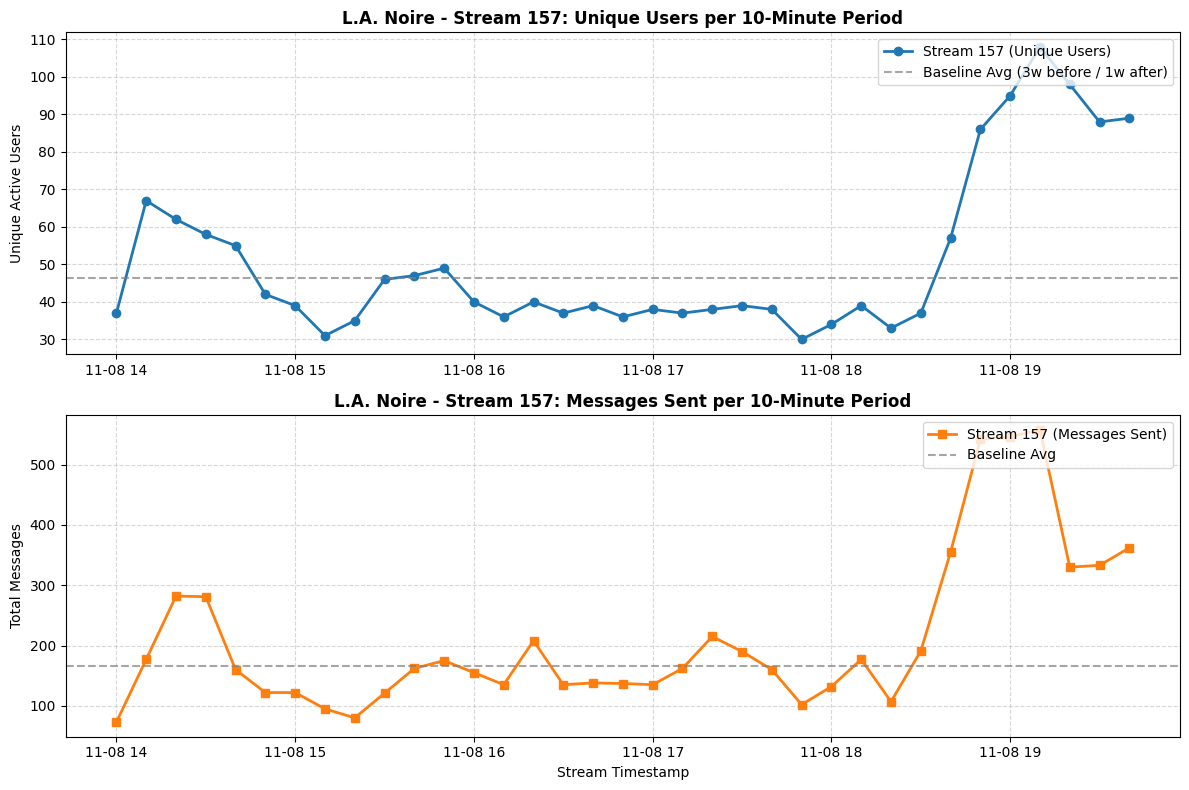

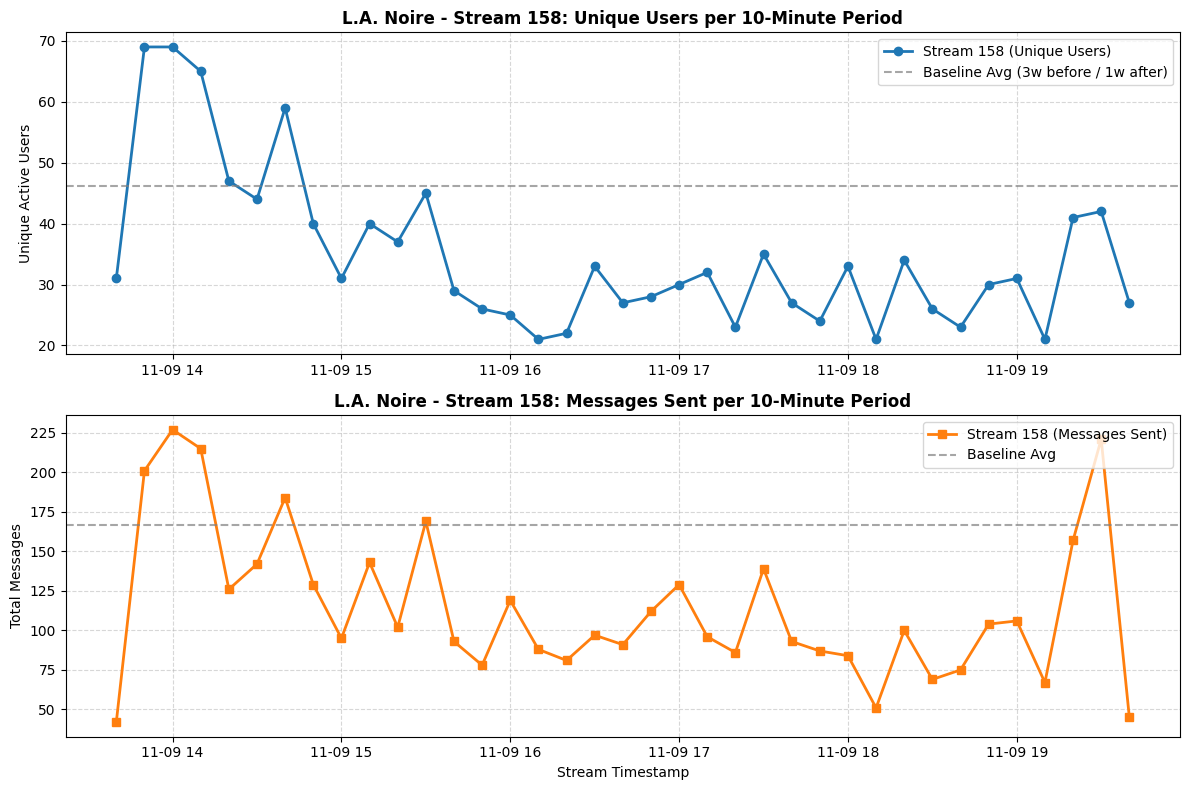

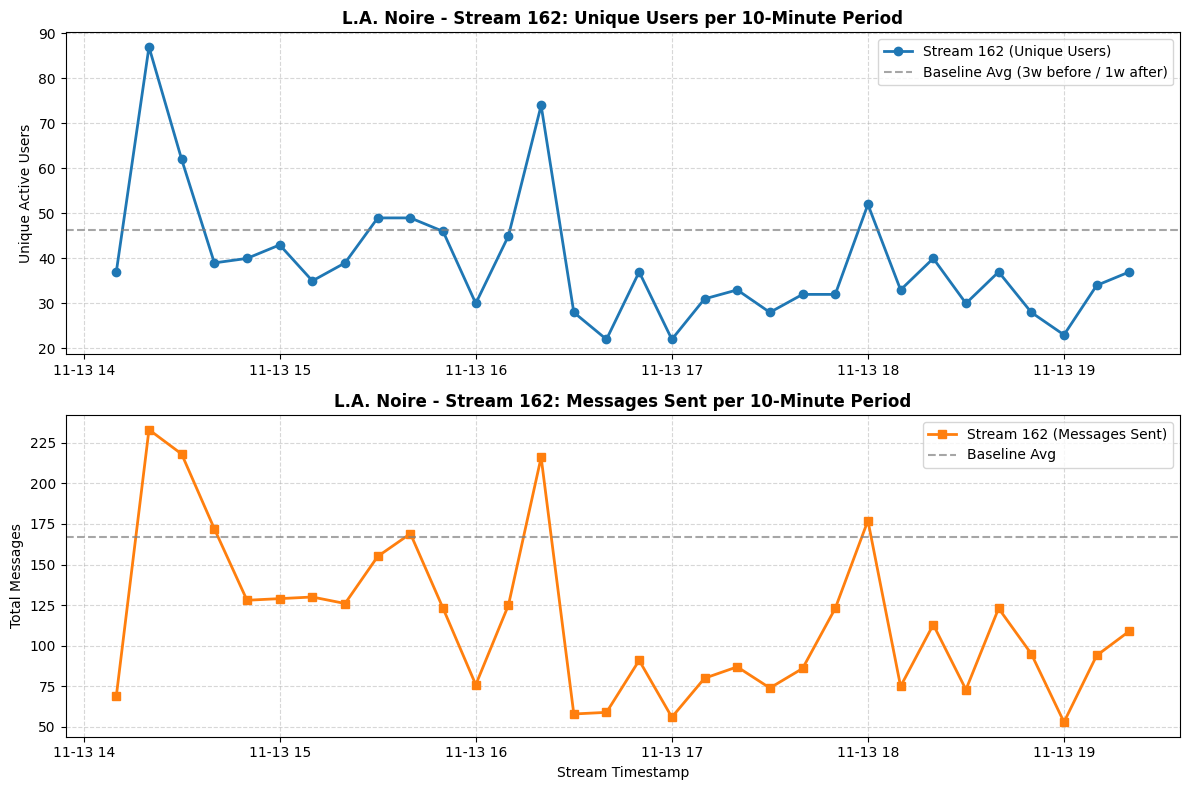

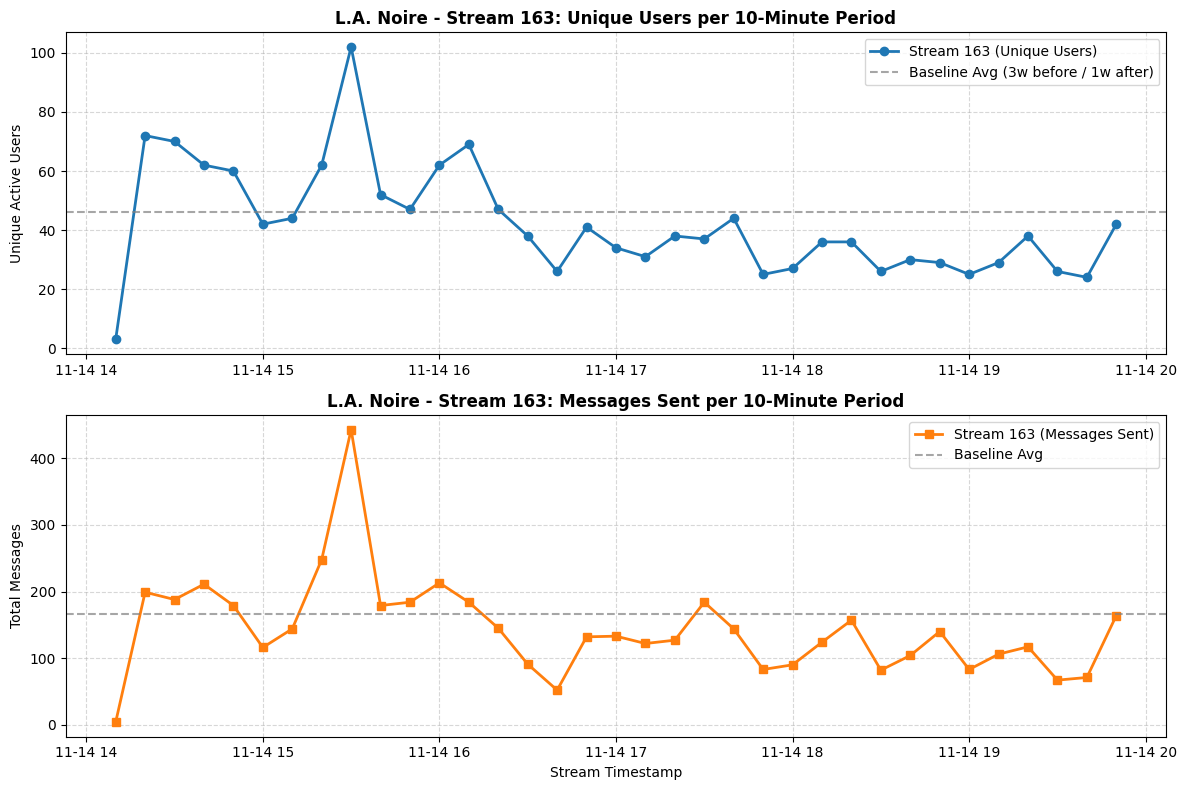

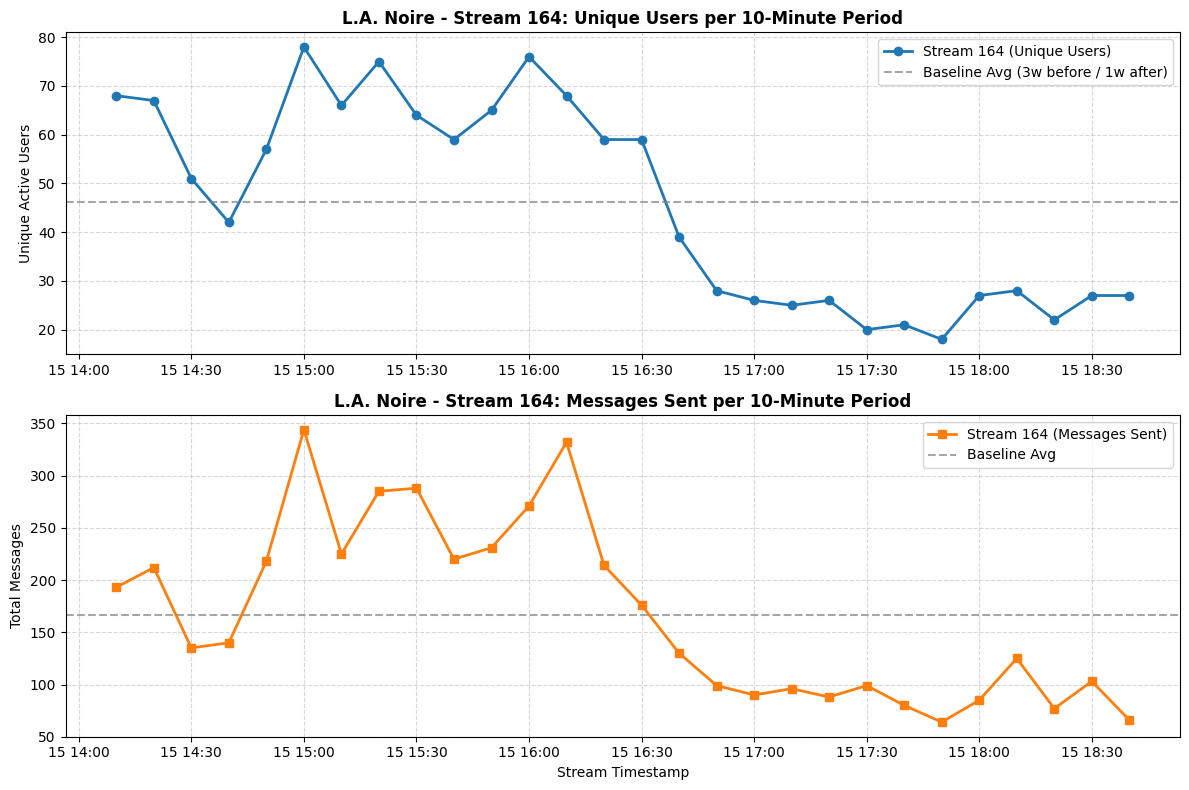

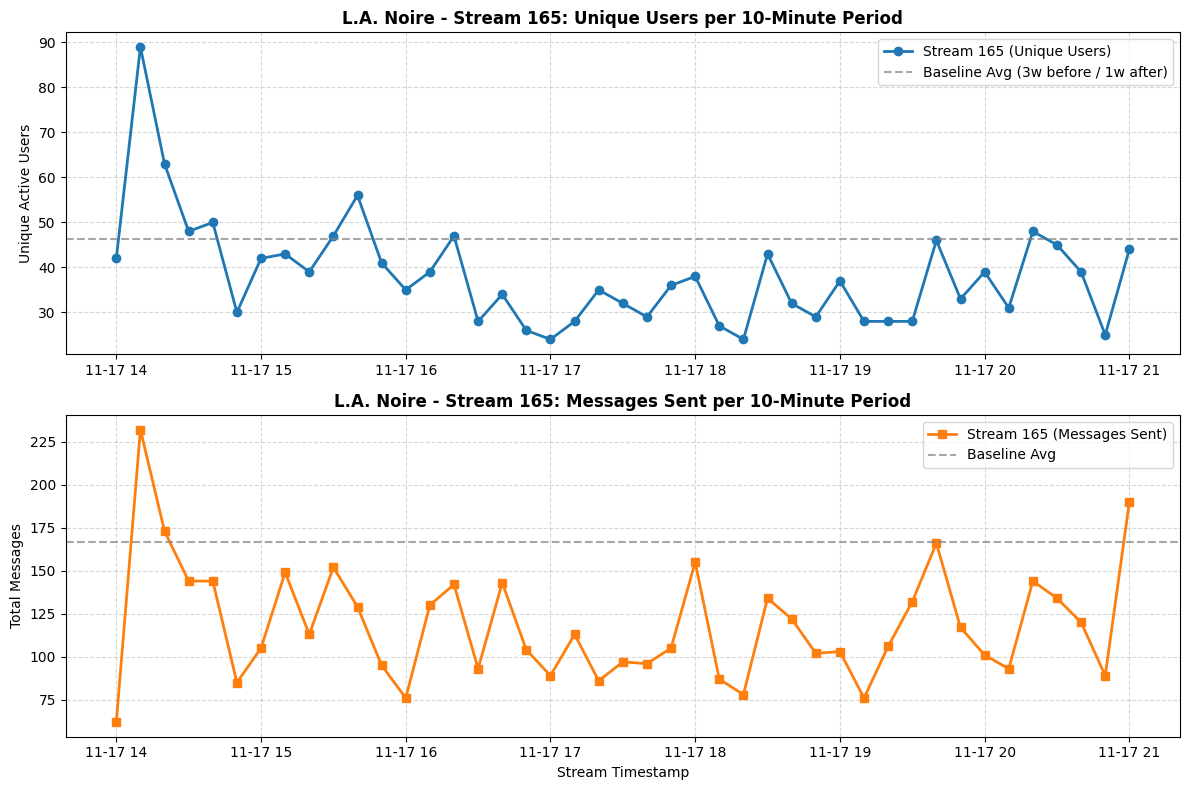

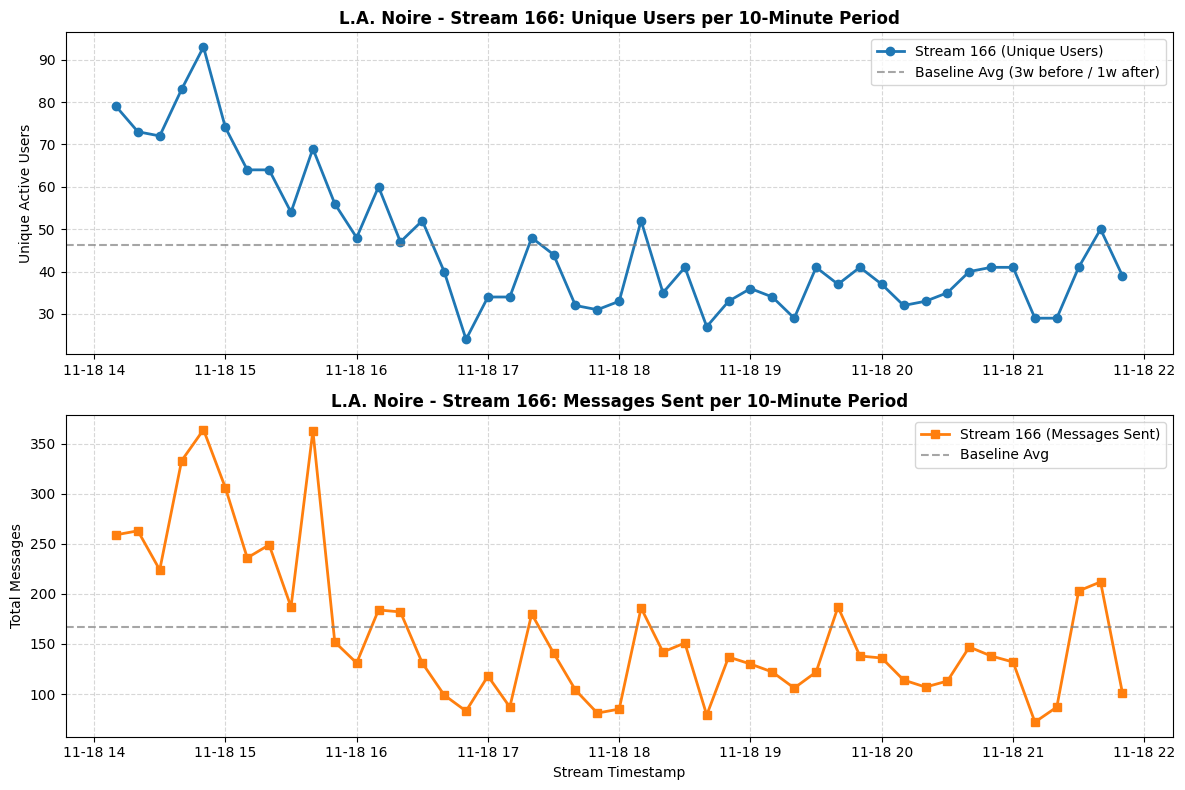

In [12]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# 1. Prepare and clean data
data['date'] = pd.to_datetime(data['date'])

# Define L.A. Noire streams
la_noire_streams = [156, 157, 158, 162, 163, 164, 165, 166]

# Establish a comparative baseline window (e.g., ~3 weeks before [~15 streams] and 1 week after [~5 streams])
min_stream_idx = min(la_noire_streams) - 15
max_stream_idx = max(la_noire_streams) + 5

# Baseline data for normalization/comparison (excluding the L.A. Noire streams themselves)
baseline_data = data[
    (data['stream'] >= min_stream_idx)
    & (data['stream'] <= max_stream_idx)
    & (~data['stream'].isin(la_noire_streams))
]

# Calculate overall baseline averages per 10-minute chunk across normal streams
baseline_indexed = baseline_data.set_index('date')
baseline_users_avg = (
    baseline_indexed.groupby('stream')
    .resample('10min')['user']
    .nunique()
    .mean()
)
baseline_msgs_avg = (
    baseline_indexed.groupby('stream')
    .resample('10min')['message']
    .count()
    .mean()
)

# 2. Generate individual 10-minute time-series graphs for each L.A. Noire stream
for s in la_noire_streams:
  stream_df = data[data['stream'] == s].copy()
  if stream_df.empty:
    continue

  # Set date as index for resampling
  stream_df = stream_df.set_index('date')

  # Resample into 10-minute bins
  unique_users = stream_df.resample('10min')['user'].nunique()
  message_counts = stream_df.resample('10min')['message'].count()

  # Create a new figure for each stream
  fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8), sharex=False)

  # Plot Unique Users
  ax1.plot(
      unique_users.index,
      unique_users.values,
      marker='o',
      color='tab:blue',
      linewidth=2,
      label=f'Stream {s} (Unique Users)',
  )
  ax1.axhline(
      y=baseline_users_avg,
      color='gray',
      linestyle='--',
      alpha=0.7,
      label='Baseline Avg (3w before / 1w after)',
  )
  ax1.set_title(
      f'L.A. Noire - Stream {s}: Unique Users per 10-Minute Period',
      fontsize=12,
      fontweight='bold',
  )
  ax1.set_ylabel('Unique Active Users')
  ax1.grid(True, linestyle='--', alpha=0.5)
  ax1.legend(loc='upper right')

  # Plot Message Count
  ax2.plot(
      message_counts.index,
      message_counts.values,
      marker='s',
      color='tab:orange',
      linewidth=2,
      label=f'Stream {s} (Messages Sent)',
  )
  ax2.axhline(
      y=baseline_msgs_avg,
      color='gray',
      linestyle='--',
      alpha=0.7,
      label='Baseline Avg',
  )
  ax2.set_title(
      f'L.A. Noire - Stream {s}: Messages Sent per 10-Minute Period',
      fontsize=12,
      fontweight='bold',
  )
  ax2.set_ylabel('Total Messages')
  ax2.set_xlabel('Stream Timestamp')
  ax2.grid(True, linestyle='--', alpha=0.5)
  ax2.legend(loc='upper right')

  plt.tight_layout()
  plt.show()

--- STREAM COMPARISON SUMMARY ---
    stream  avg_unique_users_10m  avg_messages_10m  total_unique_users  \
0      156             47.974359        191.692308                 619   
1      157             50.857143        210.142857                 613   
2      158             34.810811        114.675676                 517   
3      162             39.187500        115.468750                 482   
4      163             42.171429        143.142857                 591   
5      164             46.000000        167.357143                 461   
6      165             38.302326        118.744186                 556   
7      166             45.978723        161.787234                 663   
8      180             41.800000        130.320000                 440   
9      181             37.880952        151.952381                 573   
10     184             41.041379        158.565517                1669   

    total_messages  messages_per_user        game  
0             7476       

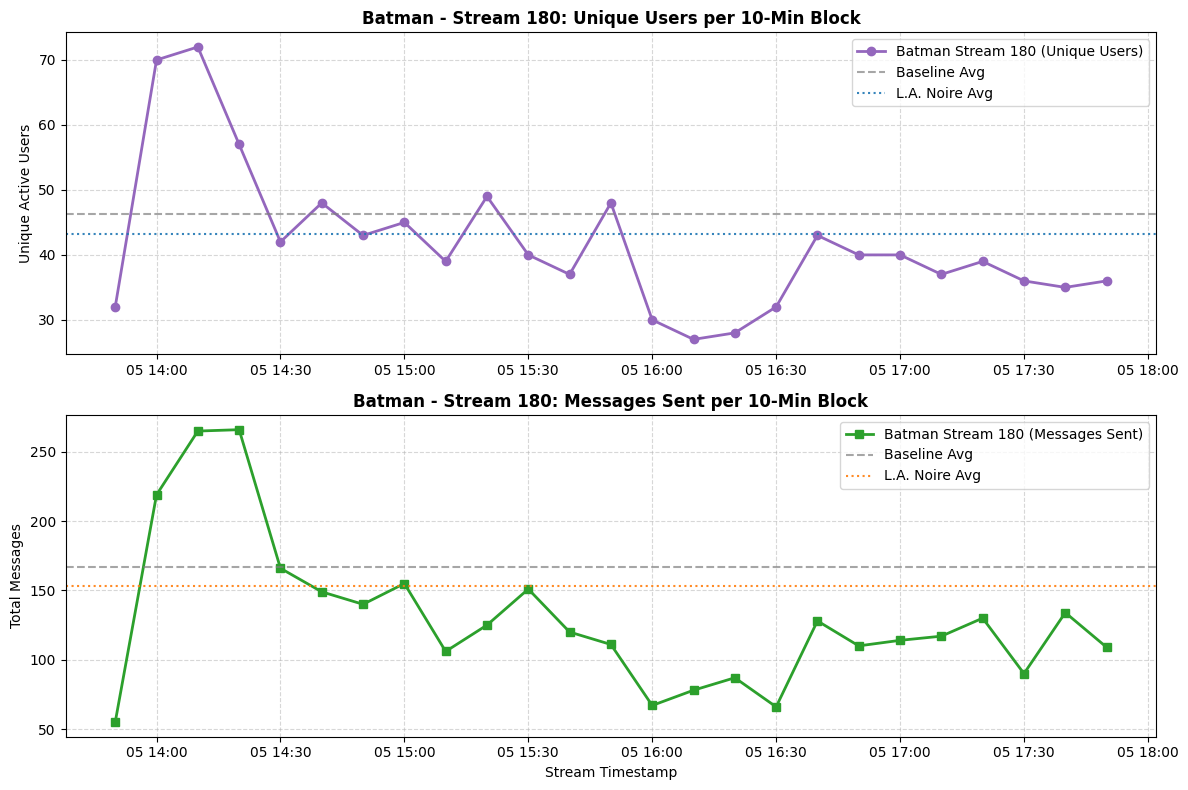

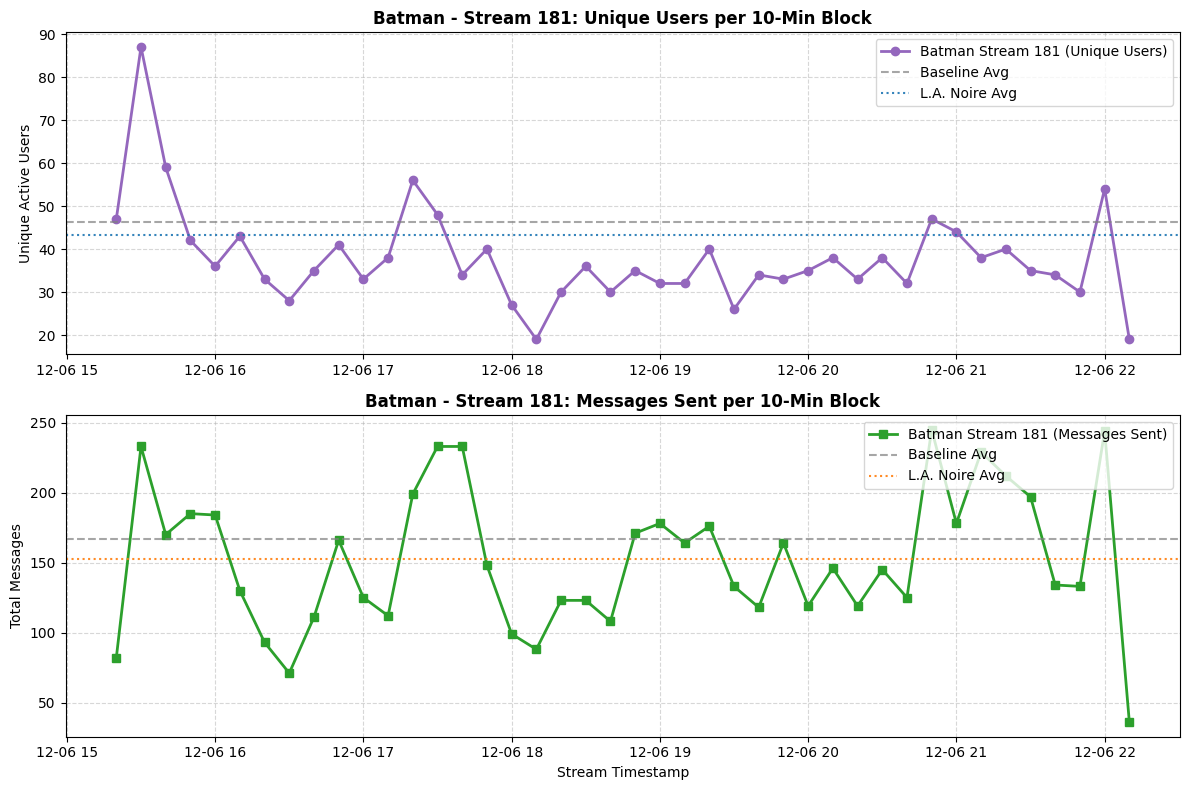

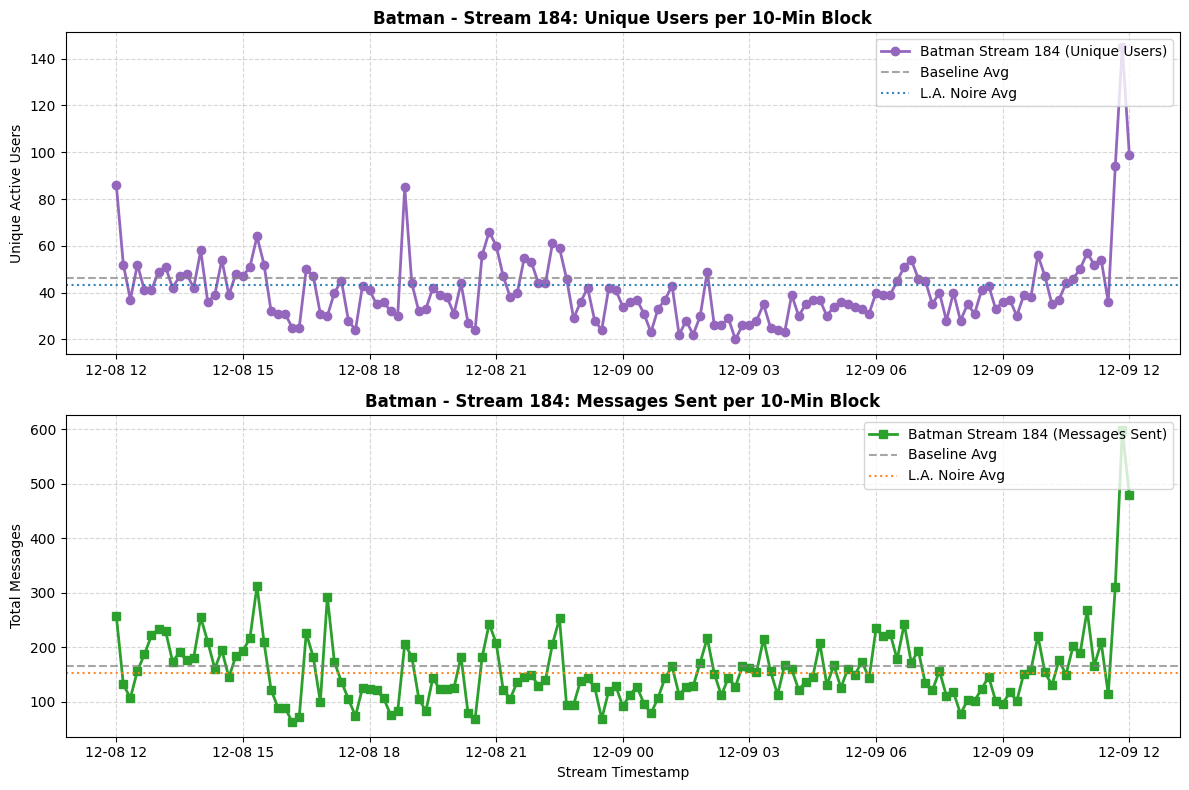

C:\Users\Kardo\AppData\Local\Temp\ipykernel_5888\1867346786.py:140: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
C:\Users\Kardo\AppData\Local\Temp\ipykernel_5888\1867346786.py:156: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


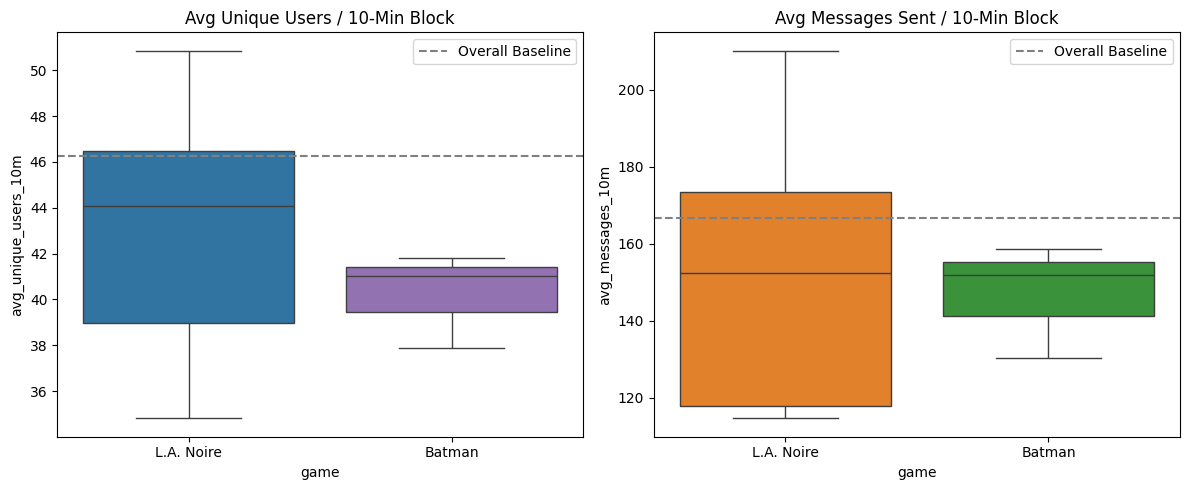

In [13]:
# --- Batman vs L.A. Noire Comparison Code ---

batman_streams = [180, 181, 184]

# 1. Calculate per-stream summaries across both game runs
la_noire_df = data[data['stream'].isin(la_noire_streams)]
batman_df = data[data['stream'].isin(batman_streams)]


def get_stream_metrics(df):
  # Group by stream to compute total messages, total unique users, and mean 10-min activity
  indexed = df.set_index('date')

  users_per_10m = (
      indexed.groupby('stream')
      .resample('10min')['user']
      .nunique()
      .groupby('stream')
      .mean()
  )
  msgs_per_10m = (
      indexed.groupby('stream')
      .resample('10min')['message']
      .count()
      .groupby('stream')
      .mean()
  )

  tot_users = df.groupby('stream')['user'].nunique()
  tot_msgs = df.groupby('stream')['message'].count()

  summary = pd.DataFrame({
      'avg_unique_users_10m': users_per_10m,
      'avg_messages_10m': msgs_per_10m,
      'total_unique_users': tot_users,
      'total_messages': tot_msgs,
  })
  # Chatter depth ratio: messages sent per unique viewer
  summary['messages_per_user'] = summary['total_messages'] / (
      summary['total_unique_users'].replace(0, 1)
  )
  return summary


la_noire_summary = get_stream_metrics(la_noire_df)
la_noire_summary['game'] = 'L.A. Noire'

batman_summary = get_stream_metrics(batman_df)
batman_summary['game'] = 'Batman'

combined_summary = pd.concat([la_noire_summary, batman_summary]).reset_index()

# Print metrics for quick verification
print('--- STREAM COMPARISON SUMMARY ---')
print(combined_summary)

# 2. Plot Batman streams 10-min breakdowns & compare to L.A. Noire / Baseline averages
for s in batman_streams:
  s_df = data[data['stream'] == s].copy()
  if s_df.empty:
    continue

  s_indexed = s_df.set_index('date')
  unique_users = s_indexed.resample('10min')['user'].nunique()
  message_counts = s_indexed.resample('10min')['message'].count()

  fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8), sharex=False)

  # Plot Batman Unique Users vs. Baseline & L.A. Noire average
  ax1.plot(
      unique_users.index,
      unique_users.values,
      marker='o',
      color='tab:purple',
      linewidth=2,
      label=f'Batman Stream {s} (Unique Users)',
  )
  ax1.axhline(
      y=baseline_users_avg,
      color='gray',
      linestyle='--',
      alpha=0.7,
      label='Baseline Avg',
  )
  ax1.axhline(
      y=la_noire_summary['avg_unique_users_10m'].mean(),
      color='tab:blue',
      linestyle=':',
      alpha=0.9,
      label='L.A. Noire Avg',
  )
  ax1.set_title(
      f'Batman - Stream {s}: Unique Users per 10-Min Block',
      fontsize=12,
      fontweight='bold',
  )
  ax1.set_ylabel('Unique Active Users')
  ax1.grid(True, linestyle='--', alpha=0.5)
  ax1.legend(loc='upper right')

  # Plot Batman Messages vs. Baseline & L.A. Noire average
  ax2.plot(
      message_counts.index,
      message_counts.values,
      marker='s',
      color='tab:green',
      linewidth=2,
      label=f'Batman Stream {s} (Messages Sent)',
  )
  ax2.axhline(
      y=baseline_msgs_avg,
      color='gray',
      linestyle='--',
      alpha=0.7,
      label='Baseline Avg',
  )
  ax2.axhline(
      y=la_noire_summary['avg_messages_10m'].mean(),
      color='tab:orange',
      linestyle=':',
      alpha=0.9,
      label='L.A. Noire Avg',
  )
  ax2.set_title(
      f'Batman - Stream {s}: Messages Sent per 10-Min Block',
      fontsize=12,
      fontweight='bold',
  )
  ax2.set_ylabel('Total Messages')
  ax2.set_xlabel('Stream Timestamp')
  ax2.grid(True, linestyle='--', alpha=0.5)
  ax2.legend(loc='upper right')

  plt.tight_layout()
  plt.show()

# 3. Overall Side-by-Side Comparison Boxplot
fig, (ax_box1, ax_box2) = plt.subplots(1, 2, figsize=(12, 5))

sns.boxplot(
    x='game',
    y='avg_unique_users_10m',
    data=combined_summary,
    ax=ax_box1,
    palette=['tab:blue', 'tab:purple'],
)
ax_box1.axhline(
    y=baseline_users_avg,
    color='gray',
    linestyle='--',
    label='Overall Baseline',
)
ax_box1.set_title('Avg Unique Users / 10-Min Block')
ax_box1.legend()

sns.boxplot(
    x='game',
    y='avg_messages_10m',
    data=combined_summary,
    ax=ax_box2,
    palette=['tab:orange', 'tab:green'],
)
ax_box2.axhline(
    y=baseline_msgs_avg,
    color='gray',
    linestyle='--',
    label='Overall Baseline',
)
ax_box2.set_title('Avg Messages Sent / 10-Min Block')
ax_box2.legend()

plt.tight_layout()
plt.show()

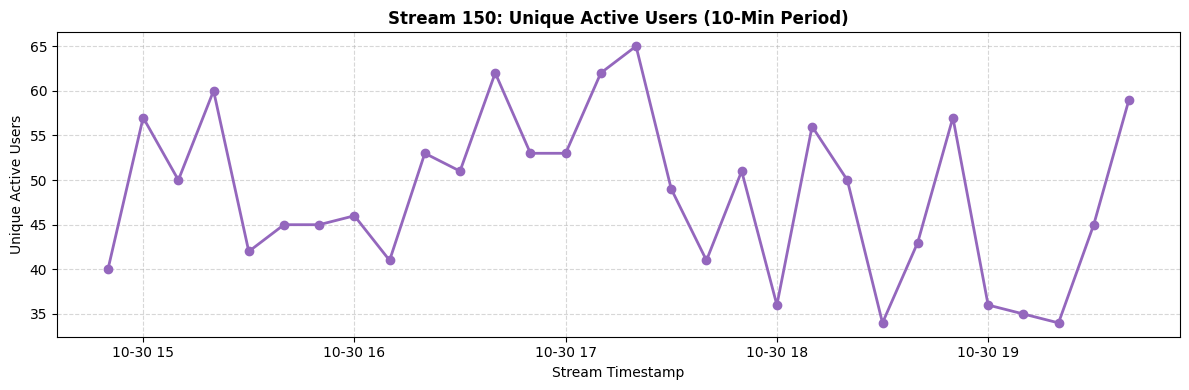

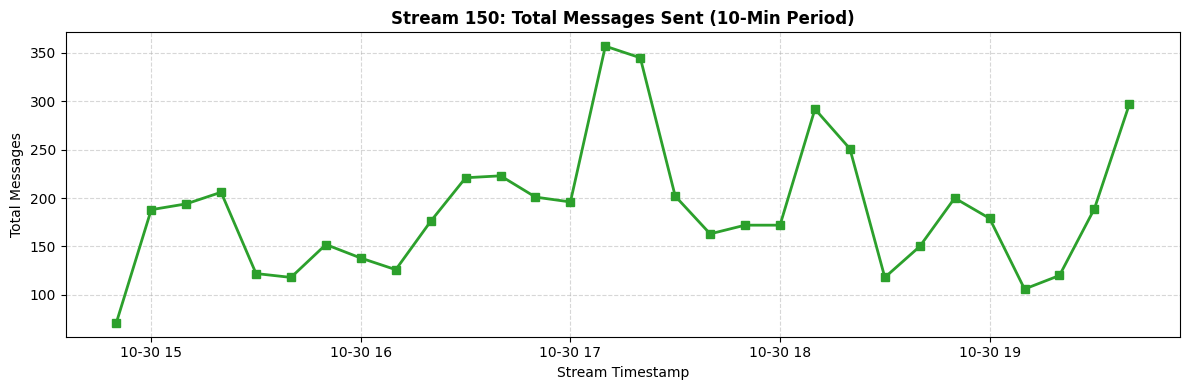

In [17]:
# --- Standalone Plots for Stream 150 (No Baselines) ---

s150_df = data[data['stream'] == 150].copy()

if not s150_df.empty:
  s150_indexed = s150_df.set_index('date')

  # Resample into 10-minute bins
  s150_users = s150_indexed.resample('10min')['user'].nunique()
  s150_msgs = s150_indexed.resample('10min')['message'].count()

  # Figure 1: Unique Active Users
  plt.figure(figsize=(12, 4))
  plt.plot(
      s150_users.index,
      s150_users.values,
      marker='o',
      color='tab:purple',
      linewidth=2,
  )
  plt.title(
      'Stream 150: Unique Active Users (10-Min Period)',
      fontsize=12,
      fontweight='bold',
  )
  plt.xlabel('Stream Timestamp')
  plt.ylabel('Unique Active Users')
  plt.grid(True, linestyle='--', alpha=0.5)
  plt.tight_layout()
  plt.show()

  # Figure 2: Messages Sent
  plt.figure(figsize=(12, 4))
  plt.plot(
      s150_msgs.index,
      s150_msgs.values,
      marker='s',
      color='tab:green',
      linewidth=2,
  )
  plt.title(
      'Stream 150: Total Messages Sent (10-Min Period)',
      fontsize=12,
      fontweight='bold',
  )
  plt.xlabel('Stream Timestamp')
  plt.ylabel('Total Messages')
  plt.grid(True, linestyle='--', alpha=0.5)
  plt.tight_layout()
  plt.show()

period            1_before  2_lanoire  3_after      gap  lanoire_vs_before_%
messages           4811.00    4902.00  2477.00  4338.00                 1.89
chatters            480.00     570.50   272.00   658.00                18.85
msgs_per_chatter      9.76       9.54     9.11     6.59                -2.27
chat_minutes        310.63     348.38   146.23   280.20                12.15
msgs_per_min         15.66      15.23    19.35    15.48                -2.74
peak_5min           218.00     222.50   245.00   162.00                 2.06
new_chatters        291.00     212.50    90.00   259.00               -26.98
regulars_present      0.52       0.36     0.22     0.42               -31.29
one_msg_share         0.41       0.43     0.45     0.40                 6.38
early_leavers         0.53       0.61     0.53     0.40                16.09
hype_rate             0.06       0.05     0.04     0.04               -27.16
game_talk_rate        0.00       0.02     0.00     0.00               812.43

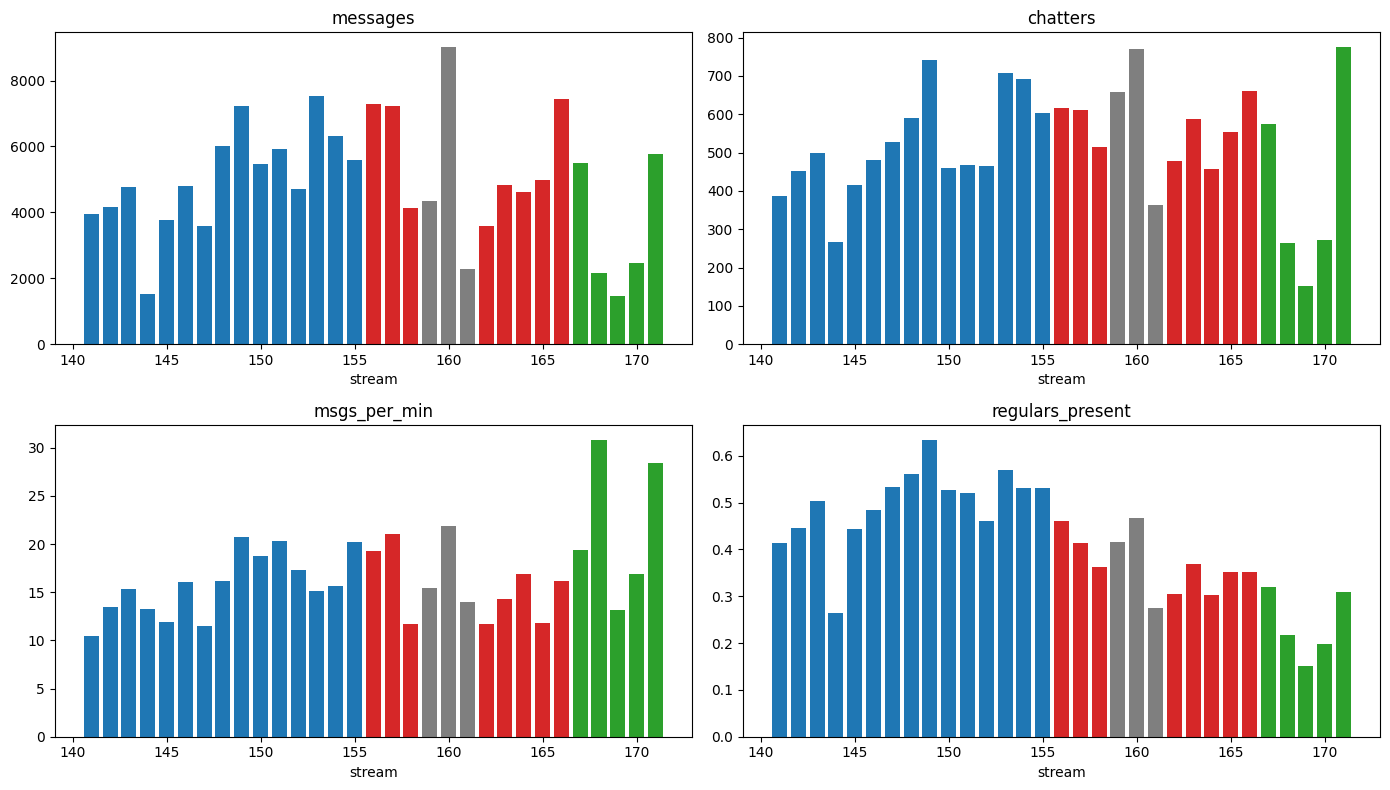

In [18]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

# ---------------- CONFIG ----------------
LA_NOIRE = [156, 157, 158, 162, 163, 164, 165, 166]
GAP      = [159, 160, 161]          # inside the span, but not LA Noire
BEFORE_N = 15                       # ~3 weeks of streams
AFTER_N  = 5                        # ~1 week of streams
BOTS     = {"nightbot", "streamelements", "moobot", "streamlabs", "fossabot"}
HYPE_RE  = re.compile(r"\b(lul|lol|kekw|omegalul|pog|poggers|w|lmao|haha+|ahah+)\b", re.I)
GAME_RE  = re.compile(r"noire|la noire|boring|detective|case|doubt", re.I)

# ---------------- PREP ----------------
d = data.copy()
d["date"] = pd.to_datetime(d["date"])
d = d[~d["user"].str.lower().isin(BOTS)]
d["msg_len"] = d["message"].astype(str).str.len()
d["hype"]    = d["message"].astype(str).apply(lambda m: bool(HYPE_RE.search(m)))
d["gamew"]   = d["message"].astype(str).apply(lambda m: bool(GAME_RE.search(m)))

first, last = min(LA_NOIRE), max(LA_NOIRE)
before_ids = list(range(first - BEFORE_N, first))
after_ids  = list(range(last + 1, last + 1 + AFTER_N))
keep = set(before_ids) | set(LA_NOIRE) | set(GAP) | set(after_ids)
d = d[d["stream"].isin(keep)]

def label(s):
    if s in LA_NOIRE: return "2_lanoire"
    if s in GAP:      return "gap"
    if s in before_ids: return "1_before"
    return "3_after"

# "regulars" = people present in >=30% of the BEFORE streams
pres_before = (d[d.stream.isin(before_ids)].groupby("user")["stream"].nunique() / len(before_ids))
regulars = set(pres_before[pres_before >= 0.30].index)

# first appearance within the analysed window (proxy for "new viewers")
first_seen = d.groupby("user")["stream"].min()

# ---------------- PER-STREAM FEATURES ----------------
rows = []
for s, g in d.groupby("stream"):
    t0, t1 = g["date"].min(), g["date"].max()
    dur = max((t1 - t0).total_seconds() / 60, 1)
    per_min = g.set_index("date").resample("1min").size()
    peak5 = per_min.rolling(5).sum().max()
    mid = t0 + (t1 - t0) / 2
    last_msg = g.groupby("user")["date"].max()
    chatters = g["user"].nunique()
    counts = g["user"].value_counts()
    rows.append(dict(
        stream=s, period=label(s),
        messages=len(g),
        chatters=chatters,
        msgs_per_chatter=len(g) / chatters,
        chat_minutes=dur,
        msgs_per_min=len(g) / dur,
        peak_5min=peak5,
        new_chatters=(first_seen[g["user"].unique()] == s).sum(),
        regulars_present=len(set(g["user"]) & regulars) / max(len(regulars), 1),
        one_msg_share=(counts == 1).mean(),
        early_leavers=(last_msg < mid).mean(),   # chatters whose last msg was in 1st half
        hype_rate=g["hype"].mean(),
        game_talk_rate=g["gamew"].mean(),
        avg_msg_len=g["msg_len"].mean(),
    ))
S = pd.DataFrame(rows).sort_values("stream").reset_index(drop=True)

# ---------------- COMPARE PERIODS ----------------
metrics = [c for c in S.columns if c not in ("stream", "period")]
summary = S.groupby("period")[metrics].median().T
base = S[S.period == "1_before"]
game = S[S.period == "2_lanoire"]
summary["lanoire_vs_before_%"] = (summary["2_lanoire"] / summary["1_before"] - 1) * 100
print(summary.round(2))

# ---------------- STATISTICAL TESTS ----------------
def perm_test(a, b, n=20000, seed=0):
    rng = np.random.default_rng(seed)
    obs = np.median(b) - np.median(a)
    pool = np.concatenate([a, b]); cnt = 0
    for _ in range(n):
        rng.shuffle(pool)
        cnt += (np.median(pool[len(a):]) - np.median(pool[:len(a)])) <= obs
    return cnt / n   # one-sided: is LA Noire LOWER?

res = []
for m in ["messages", "chatters", "msgs_per_min", "peak_5min", "msgs_per_chatter",
          "regulars_present", "new_chatters", "hype_rate"]:
    a, b = base[m].values, game[m].values
    u = stats.mannwhitneyu(b, a, alternative="less")
    # Cliff's delta (effect size): -1 = LA Noire always lower
    delta = (np.sum(b[:, None] > a) - np.sum(b[:, None] < a)) / (len(a) * len(b))
    res.append(dict(metric=m, before_median=np.median(a), lanoire_median=np.median(b),
                    mannwhitney_p=u.pvalue, perm_p=perm_test(a, b), cliffs_delta=delta))
print(pd.DataFrame(res).round(3))

# ---------------- TREND-ADJUSTED CHECK ----------------
# fit trend on non-LA-Noire streams (before + after), predict LA Noire streams
def trend_check(metric):
    ref = S[S.period.isin(["1_before", "3_after"])]
    slope, icpt, *_ = stats.linregress(ref["stream"], ref[metric])
    pred = icpt + slope * game["stream"]
    return (game[metric] / pred - 1) * 100   # % vs expected

for m in ["messages", "chatters", "msgs_per_min"]:
    r = trend_check(m)
    print(f"{m}: LA Noire streams are {r.mean():+.1f}% vs trend-expected (per stream: {r.round(0).tolist()})")

# ---------------- PLOTS ----------------
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
colors = {"1_before": "tab:blue", "2_lanoire": "tab:red", "gap": "tab:gray", "3_after": "tab:green"}
for ax, m in zip(axes.ravel(), ["messages", "chatters", "msgs_per_min", "regulars_present"]):
    ax.bar(S["stream"], S[m], color=S["period"].map(colors))
    ax.set_title(m); ax.set_xlabel("stream")
plt.tight_layout(); plt.show()

In [19]:

import pandas as pd
import numpy as np

# Streams where Dorozea played LA Noire
lan_streams = [156, 157, 158, 162, 163, 164, 165, 166]

# Make sure dates are datetime
data["date"] = pd.to_datetime(data["date"])

# Get the dates of the LA Noire streams
lan_dates = (
    data[data["stream"].isin(lan_streams)]
    .groupby("stream")["date"]
    .min()
)

first_lan_date = lan_dates.min()
last_lan_date = lan_dates.max()

print("LA Noire period:")
print(first_lan_date, "to", last_lan_date)

# Define comparison periods
before_start = first_lan_date - pd.Timedelta(days=21)
before_end = first_lan_date

after_start = last_lan_date
after_end = last_lan_date + pd.Timedelta(days=7)

# Classify streams
stream_dates = data.groupby("stream")["date"].min()

def classify_stream(stream):
    if stream in lan_streams:
        return "LA Noire"
    
    date = stream_dates[stream]

    if before_start <= date < before_end:
        return "Before"
    
    if last_lan_date < date <= after_end:
        return "After"
    
    return "Other"

# Stream-level statistics
stats = data.groupby("stream").agg(
    date=("date", "min"),
    messages=("message", "count"),
    unique_chatters=("user", "nunique"),
    active_users=("user", "nunique")
).reset_index()

stats["period"] = stats["stream"].apply(classify_stream)

# Messages per chatter
stats["messages_per_chatter"] = (
    stats["messages"] / stats["unique_chatters"]
)

# Sort chronologically
stats = stats.sort_values("stream")

print(stats[stats["period"] != "Other"].to_string(index=False))


LA Noire period:
2024-11-07 14:03:57+01:00 to 2024-11-18 14:11:30+01:00
 stream                      date  messages  unique_chatters  active_users   period  messages_per_chatter
    140 2024-10-19 14:08:45+02:00      5006              483           483   Before             10.364389
    141 2024-10-20 14:51:08+02:00      4065              390           390   Before             10.423077
    142 2024-10-21 14:12:33+02:00      4258              456           456   Before              9.337719
    143 2024-10-22 13:51:31+02:00      4918              503           503   Before              9.777336
    144 2024-10-23 14:03:12+02:00      1579              271           271   Before              5.826568
    145 2024-10-24 13:51:01+02:00      3861              418           418   Before              9.236842
    146 2024-10-26 14:07:13+02:00      4910              483           483   Before             10.165631
    147 2024-10-27 13:58:42+01:00      3675              531           531   Bef

In [20]:

comparison = stats[stats["period"] != "Other"].groupby("period").agg(
    streams=("stream", "count"),
    avg_messages=("messages", "mean"),
    median_messages=("messages", "median"),
    avg_chatters=("unique_chatters", "mean"),
    median_chatters=("unique_chatters", "median"),
    avg_messages_per_chatter=("messages_per_chatter", "mean"),
    median_messages_per_chatter=("messages_per_chatter", "median")
)

comparison = comparison.reindex(["Before", "LA Noire", "After"])

print(comparison.round(2))


          streams  avg_messages  median_messages  avg_chatters  \
period                                                           
Before         16       5166.31           4962.0        517.62   
LA Noire        8       5646.88           5058.0        562.75   
After           4       2959.25           2368.5        318.50   

          median_chatters  avg_messages_per_chatter  \
period                                                
Before              483.0                      9.88   
LA Noire            573.5                      9.91   
After               270.5                      9.20   

          median_messages_per_chatter  
period                                 
Before                          10.16  
LA Noire                         9.67  
After                            9.37  


In [21]:

before = comparison.loc["Before"]
lan = comparison.loc["LA Noire"]
after = comparison.loc["After"]

metrics = [
    "avg_messages",
    "avg_chatters",
    "avg_messages_per_chatter"
]

for metric in metrics:
    before_value = before[metric]
    lan_value = lan[metric]
    after_value = after[metric]

    change_lan = (lan_value / before_value - 1) * 100
    change_after = (after_value / lan_value - 1) * 100

    print(f"\n{metric}")
    print(f"LA Noire vs Before: {change_lan:+.2f}%")
    print(f"After vs LA Noire: {change_after:+.2f}%")



avg_messages
LA Noire vs Before: +9.30%
After vs LA Noire: -47.59%

avg_chatters
LA Noire vs Before: +8.72%
After vs LA Noire: -43.40%

avg_messages_per_chatter
LA Noire vs Before: +0.30%
After vs LA Noire: -7.14%


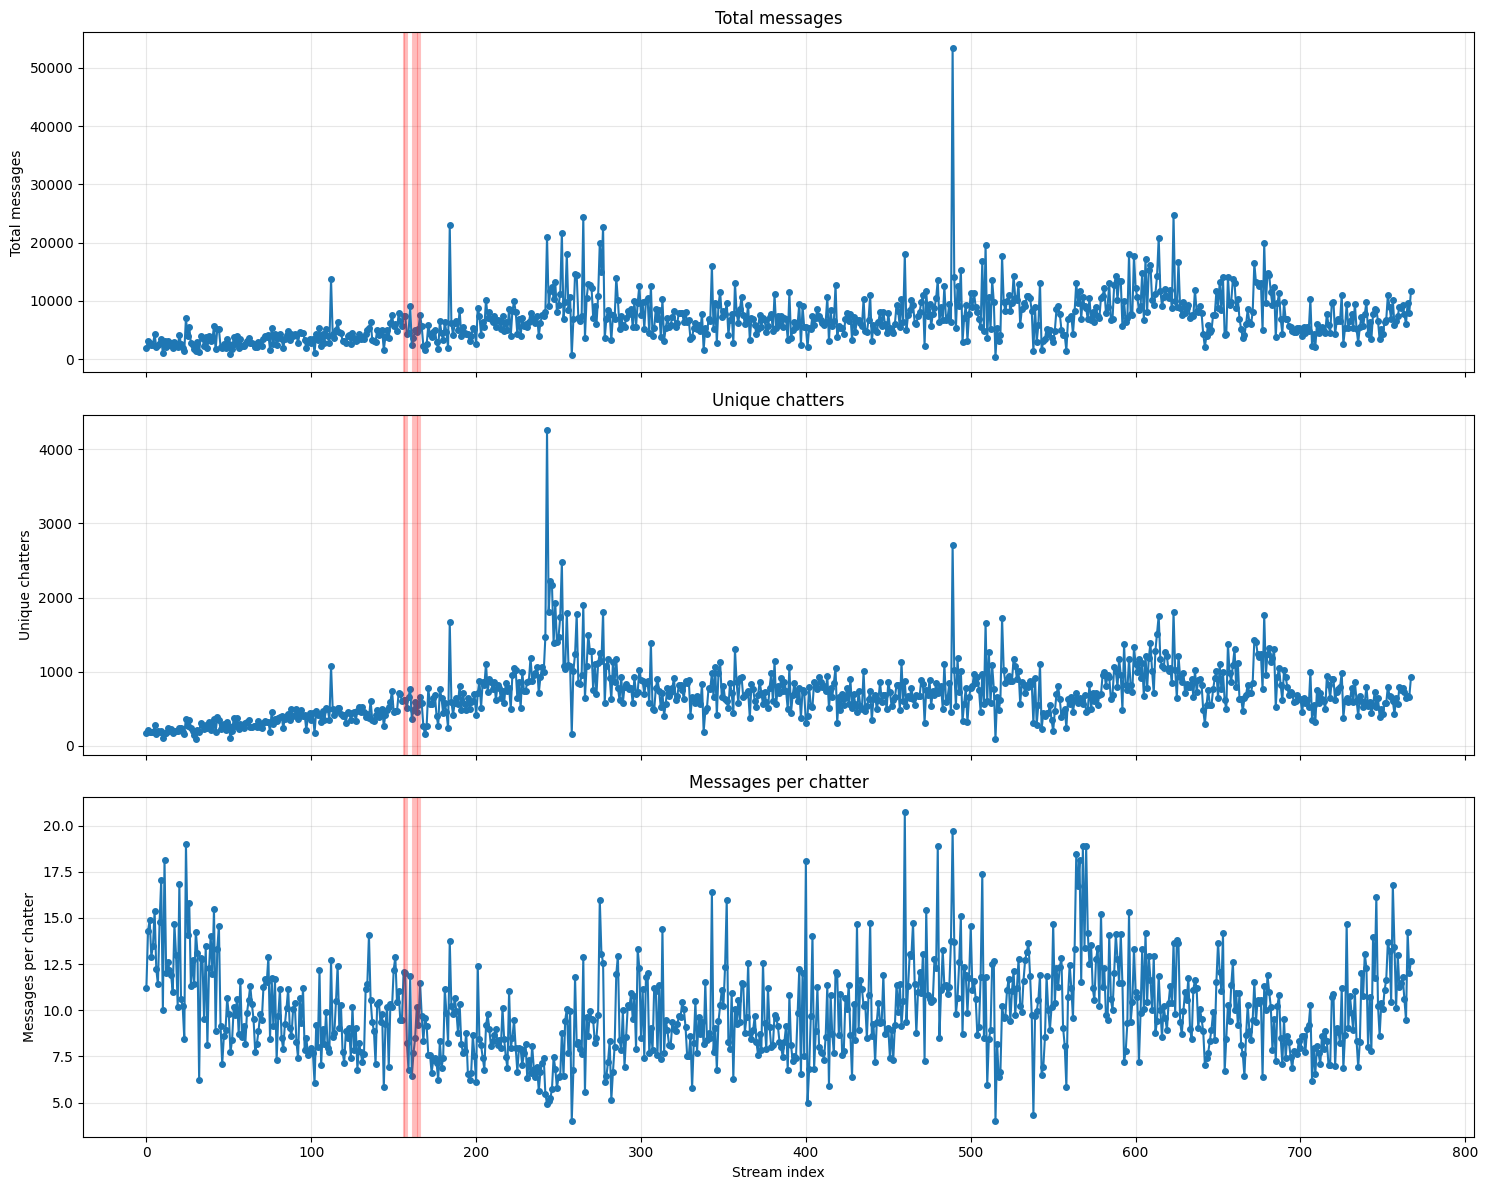

In [22]:

import matplotlib.pyplot as plt

fig, axes = plt.subplots(3, 1, figsize=(15, 12), sharex=True)

metrics = [
    ("messages", "Total messages"),
    ("unique_chatters", "Unique chatters"),
    ("messages_per_chatter", "Messages per chatter")
]

for ax, (metric, title) in zip(axes, metrics):
    ax.plot(
        stats["stream"],
        stats[metric],
        marker="o",
        markersize=4
    )

    # Highlight LA Noire streams
    for stream in lan_streams:
        ax.axvline(stream, color="red", alpha=0.25)

    ax.set_title(title)
    ax.set_ylabel(title)
    ax.grid(alpha=0.3)

axes[-1].set_xlabel("Stream index")

plt.tight_layout()
plt.show()


In [23]:

# Users who chatted during the 3 weeks before LA Noire
before_users = set(
    data[
        (data["date"] >= before_start) &
        (data["date"] < before_end)
    ]["user"].unique()
)

# Users who chatted during LA Noire
lan_users = set(
    data[data["stream"].isin(lan_streams)]["user"].unique()
)

# Users who returned after LA Noire
after_users = set(
    data[
        (data["date"] > last_lan_date) &
        (data["date"] <= after_end)
    ]["user"].unique()
)

returning = before_users & lan_users
disappeared = before_users - lan_users
new_during_lan = lan_users - before_users
returned_after = disappeared & after_users

print("Regular users before:", len(before_users))
print("Participated during LA Noire:", len(returning))
print("Did not participate:", len(disappeared))
print("New users during LA Noire:", len(new_during_lan))
print("Disappeared but returned afterwards:", len(returned_after))

print(
    "Retention:",
    round(len(returning) / len(before_users) * 100, 2),
    "%"
)


Regular users before: 4601
Participated during LA Noire: 1111
Did not participate: 3490
New users during LA Noire: 1755
Disappeared but returned afterwards: 131
Retention: 24.15 %


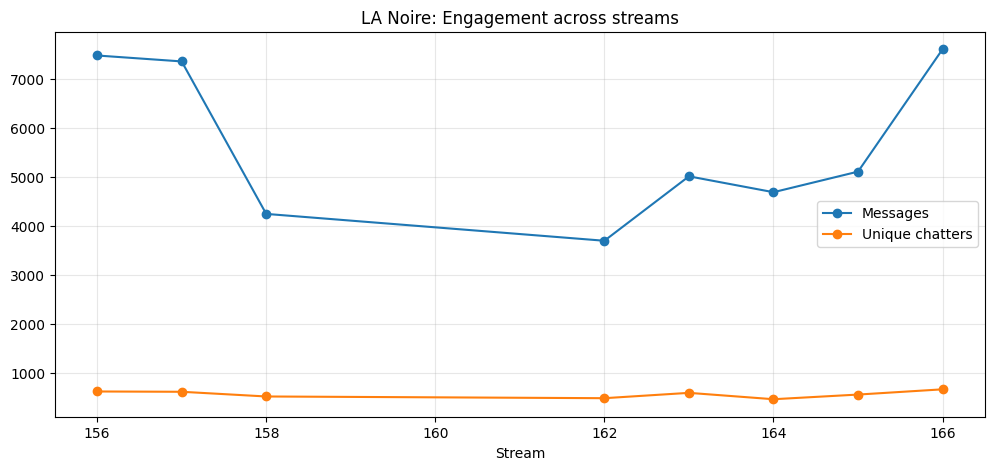

In [24]:

lan_stats = stats[stats["stream"].isin(lan_streams)].copy()

lan_stats = lan_stats.sort_values("stream")

fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    lan_stats["stream"],
    lan_stats["messages"],
    marker="o",
    label="Messages"
)

ax.plot(
    lan_stats["stream"],
    lan_stats["unique_chatters"],
    marker="o",
    label="Unique chatters"
)

ax.set_title("LA Noire: Engagement across streams")
ax.set_xlabel("Stream")
ax.legend()
ax.grid(alpha=0.3)

plt.show()
